In [13]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from pathlib import Path
import pandas as pd

In [14]:
#PLT 한글 깨짐 방지코드
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

In [8]:
from pathlib import Path

import pandas as pd


# 주피터 노트북에서는 __file__이 없으므로 CSV 폴더 경로를 직접 지정합니다.
# 노트북 실행 위치(cwd)는 practice/day32 이므로 ../../ 로 저장소 루트까지 올라갑니다.
BASE = Path("../../lectures/week9/3일차실습_20_261109_11")
data = BASE / "03-02_센서_고장_판별_이상구간샘플.csv"
EVENTS = BASE / "03-02_센서_고장_판별_정비알람이력.csv"

df = pd.read_csv(data, parse_dates=["timestamp"])
events = pd.read_csv(EVENTS, parse_dates=["event_time"])
print("shape:", df.shape)
print(df.isna().sum())
print(events.to_string(index=False))


shape: (288, 10)
timestamp           0
MTR02_TEMP          0
MTR02_TEMP_B        0
MTR02_VIB_H        18
MTR02_CURRENT       0
MTR02_RUN           0
HYD02_PRESS         0
HYD02_PRESS_ACC     0
HYD02_FLOW          0
FUR02_TEMP_Z1       0
dtype: int64
         event_time             tag event_type               description
2026-04-01 18:00:00       MTR02_RUN       설비정지          계획 정지 - 소재 교체 작업
2026-04-01 21:00:00       MTR02_RUN       설비정지             정지 해제 - 운전 재개
2026-04-02 06:00:00     MTR02_VIB_H       통신장애           계측 네트워크 스위치 재기동
2026-04-02 09:00:00     MTR02_VIB_H       통신장애                  통신 복구 확인
2026-04-02 12:00:00 HYD02_PRESS_ACC         알람           어큐뮬레이터 압력 상한 도달
2026-04-01 10:00:00     HYD02_PRESS         알람            공급 압력 변동 없음 경고
2026-03-15 09:00:00      MTR02_TEMP         교정 베어링 온도 센서 정기 교정 - 보정량 미기재
2026-02-20 14:00:00      HYD02_FLOW       센서교체            유량계 교체 - 동일 사양


In [ ]:
# TODO 1: MTR02 / HYD02 / FUR02 케이스 중 하나를 골라 물리량과 단위를 정리하세요.


In [9]:

tag_info = {
    "MTR02_TEMP":    {"물리량": "베어링 온도 (센서 1)",          "단위": "degC (추정)", "참고 태그": "FAN01_TEMP (degC)"},
    "MTR02_TEMP_B":  {"물리량": "베어링 온도 (센서 2, 비교용)",   "단위": "degC (추정)", "참고 태그": "FAN01_TEMP (degC)"},
    "MTR02_VIB_H":   {"물리량": "수평 진동 속도 RMS",             "단위": "mm/s (추정)", "참고 태그": "MTR01_VIB_H (mm/s)"},
    "MTR02_CURRENT": {"물리량": "모터 전류",                      "단위": "A (추정)",    "참고 태그": "MTR01_CURRENT (A)"},
    "MTR02_RUN":     {"물리량": "가동 상태 (1=운전, 0=정지)",      "단위": "없음",        "참고 태그": "없음 (0/1 플래그)"},
}

tag_table = pd.DataFrame(tag_info).T
print(tag_table.to_string())


                              물리량         단위               참고 태그
MTR02_TEMP          베어링 온도 (센서 1)  degC (추정)   FAN01_TEMP (degC)
MTR02_TEMP_B   베어링 온도 (센서 2, 비교용)  degC (추정)   FAN01_TEMP (degC)
MTR02_VIB_H          수평 진동 속도 RMS  mm/s (추정)  MTR01_VIB_H (mm/s)
MTR02_CURRENT               모터 전류     A (추정)   MTR01_CURRENT (A)
MTR02_RUN      가동 상태 (1=운전, 0=정지)         없음        없음 (0/1 플래그)


In [6]:
# TODO 2: 결측 구간, 가동 중 최장 동일값 반복, 최대값 반복 횟수, 구간별 변동 폭을 계산하세요.


In [25]:
# 결측 구간 찾기 (한 줄)
missing_times = df.loc[df["MTR02_VIB_H"].isna(), "timestamp"]

print("결측 개수:", len(missing_times))
print("결측 시작:", missing_times.min())
print("결측 끝:", missing_times.max())


결측 개수: 18
결측 시작: 2026-04-02 06:00:00
결측 끝: 2026-04-02 08:50:00


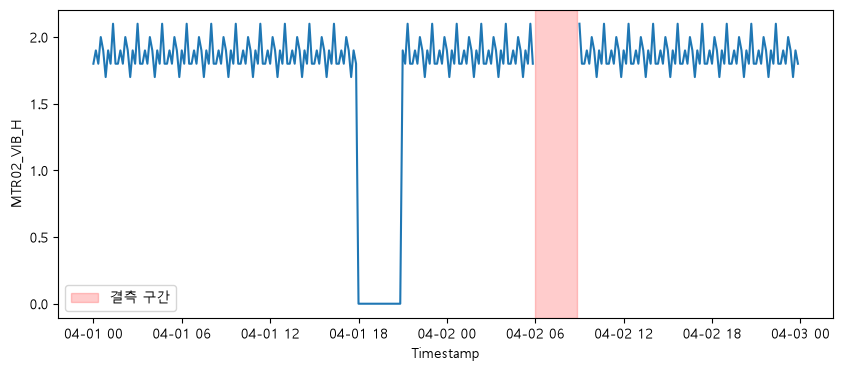

In [73]:

plt.figure(figsize=(10, 4))
plt.plot(df['timestamp'], df['MTR02_VIB_H'])               # x축: 시간
plt.axvspan(missing_times.min(), missing_times.max(), color='red', alpha=0.2, label='결측 구간')  # 결측 구간 색칠
plt.xlabel('Timestamp')
plt.ylabel('MTR02_VIB_H')
plt.legend()
plt.show()


In [47]:
# TODO 2: 결측 구간, 가동 중 최장 동일값 반복, 최대값 반복 횟수, 구간별 변동 폭을 계산하세요.


In [74]:
m2 = df[df["MTR02_RUN"] == 1]
m2.head()

,timestamp,MTR02_TEMP,MTR02_TEMP_B,MTR02_VIB_H,MTR02_CURRENT,MTR02_RUN,HYD02_PRESS,HYD02_PRESS_ACC,HYD02_FLOW,FUR02_TEMP_Z1
0,2026-04-01 00:00:00,48.0,48.0,1.8,62.5,1,152.0,148.0,118.0,1195.0
1,2026-04-01 00:10:00,48.0,48.0,1.9,63.0,1,153.0,148.0,118.5,1196.0
2,2026-04-01 00:20:00,48.5,48.5,1.8,62.0,1,152.0,147.0,117.5,1194.0
3,2026-04-01 00:30:00,48.0,48.0,2.0,64.0,1,151.0,148.0,118.0,1195.0
4,2026-04-01 00:40:00,48.5,48.5,1.9,63.5,1,153.0,149.0,118.5,1196.0


In [46]:
m2.columns.tolist()

['timestamp',
 'MTR02_TEMP',
 'MTR02_TEMP_B',
 'MTR02_VIB_H',
 'MTR02_CURRENT',
 'MTR02_RUN',
 'HYD02_PRESS',
 'HYD02_PRESS_ACC',
 'HYD02_FLOW',
 'FUR02_TEMP_Z1']

In [65]:
cols = ["MTR02_TEMP", "MTR02_TEMP_B", "MTR02_VIB_H", "MTR02_CURRENT"]



In [ ]:
#가동 중 최장 동일값 반복

for col in cols:
    s = m2[col]
    결과 = s.groupby(s.ne(s.shift()).cumsum()).agg(["first", "size"]).sort_values("size").iloc[-1]
    print(col, "값:", 결과["first"], "연속:", 결과["size"])

#MTR02_TEMP 값: 50.0 연속: 4.0


MTR02_TEMP 값: 50.0 연속: 4.0
MTR02_TEMP_B 값: 54.0 연속: 3.0
MTR02_VIB_H 값: 1.8 연속: 2.0
MTR02_CURRENT 값: 62.0 연속: 1.0


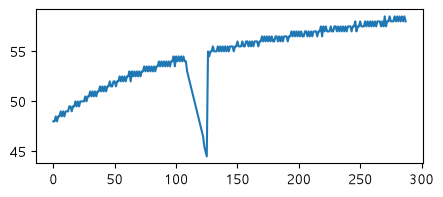

In [69]:
plt.figure(figsize=(5, 2))
plt.plot(df['MTR02_TEMP'])
plt.show()

In [68]:
#최대값 반복 횟수

for col in cols:
    s = m2[col]
    print(col, "최대값:", s.max(), "/ 반복 횟수:", (s == s.max()).sum())

#MTR02_TEMP_B 최대값: 54.0 / 반복 횟수: 58


MTR02_TEMP 최대값: 58.5 / 반복 횟수: 7
MTR02_TEMP_B 최대값: 54.0 / 반복 횟수: 58
MTR02_VIB_H 최대값: 2.1 / 반복 횟수: 25
MTR02_CURRENT 최대값: 64.5 / 반복 횟수: 26


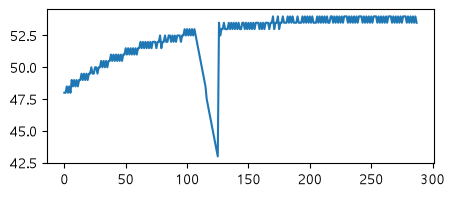

In [53]:
plt.figure(figsize=(5, 2))
plt.plot(df['MTR02_TEMP_B'])
plt.show()

In [ ]:
df_run = df[df["MTR02_RUN"] == 1].set_index("timestamp")   

최대 = df_run["HYD02_FLOW"].resample("6h").max()
최소 = df_run["HYD02_FLOW"].resample("6h").min()
변동 = 최대 - 최소                       

처음 = 변동.iloc[0]                      
마지막 = 변동.iloc[-1]                   
print("처음:", round(처음, 2), "마지막:", round(마지막, 2))
print("차이:", round(마지막 - 처음, 2))
print("배율:", round(마지막 / 처음, 2), "배")


처음: 1.5 마지막: 5.7
차이: 4.2
배율: 3.8 배


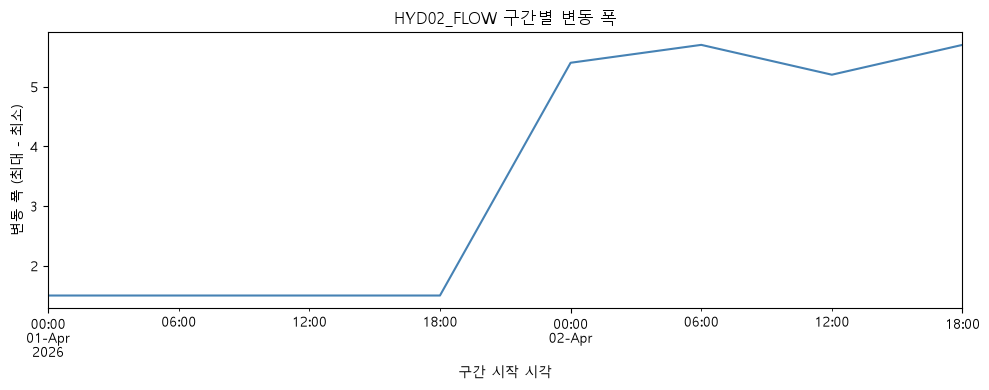

In [ ]:
df_run = df[df["MTR02_RUN"] == 1].set_index("timestamp")   
최대 = df_run["HYD02_FLOW"].resample("6h").max()
최소 = df_run["HYD02_FLOW"].resample("6h").min()
변동 = 최대 - 최소                                         

plt.figure(figsize=(10, 4))
변동.plot(kind="line", color="steelblue")                  
plt.xticks(rotation=0)
plt.xlabel("구간 시작 시각")
plt.ylabel("변동 폭 (최대 - 최소)")
plt.title("HYD02_FLOW 구간별 변동 폭")
plt.tight_layout()
plt.show()


In [ ]:
# TODO 3: 같은 물리량 센서끼리 비교하고 알람·정비 이력과 시각을 대조하세요.

In [ ]:
2026-04-01 18:00:00,MTR02_RUN,설비정지,계획 정지 - 소재 교체 작업
2026-04-01 21:00:00,MTR02_RUN,설비정지,정지 해제 - 운전 재개
2026-04-02 06:00:00,MTR02_VIB_H,통신장애,계측 네트워크 스위치 재기동
2026-04-02 09:00:00,MTR02_VIB_H,통신장애,통신 복구 확인

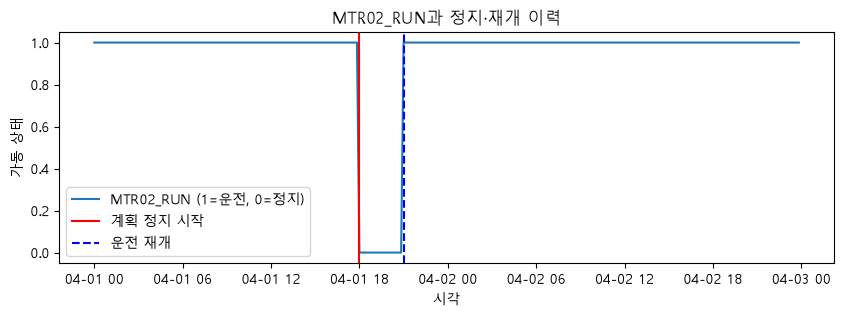

In [86]:
plt.figure(figsize=(10, 3))
plt.plot(df["timestamp"], df["MTR02_RUN"], label="MTR02_RUN (1=운전, 0=정지)")
plt.axvline(pd.Timestamp("2026-04-01 18:00:00"), color="red", linestyle="-", label="계획 정지 시작")
plt.axvline(pd.Timestamp("2026-04-01 21:00:00"), color="blue", linestyle="--", label="운전 재개")
plt.xlabel("시각")
plt.ylabel("가동 상태")
plt.title("MTR02_RUN과 정지·재개 이력")
plt.legend()
plt.show()


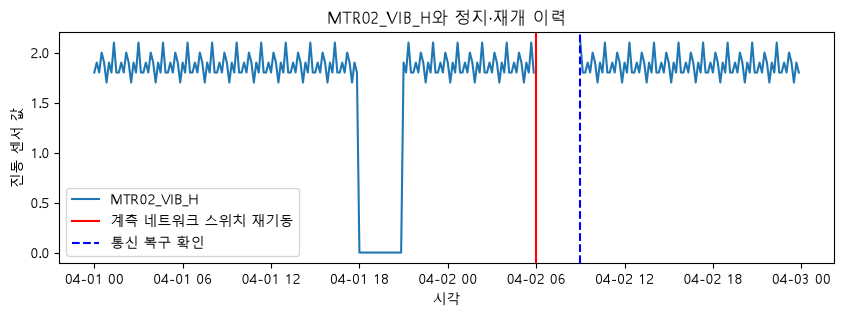

In [85]:
plt.figure(figsize=(10, 3))
plt.plot(df["timestamp"], df["MTR02_VIB_H"], label="MTR02_VIB_H")
plt.axvline(pd.Timestamp("2026-04-02 06:00:00"), color="red", linestyle="-", label="계측 네트워크 스위치 재기동")
plt.axvline(pd.Timestamp("2026-04-02 09:00:00"), color="blue", linestyle="--", label="통신 복구 확인")
plt.xlabel("시각")
plt.ylabel("진동 센서 값")
plt.title("MTR02_VIB_H와 정지·재개 이력")
plt.legend()
plt.show()


In [84]:
# TODO 4: 각 이상을 설비 현상 / 센서 이상 / 판단 보류로 나누고 근거·추가 자료·처리 방침을 작성하세요.


In [ ]:
설비 현상: 설비가 실제로 그렇게 움직인 것입니다. 
정지, 압력 상한 도달 같은 경우입니다.
센서 이상: 설비는 정상인데 센서나 통신이 잘못 보낸 것입니다. 
결측, 통신 두절, 고착 같은 경우입니다.
판단 보류: 두 경우를 자료만으로 가릴 수 없는 것입니다. 
이때는 무엇을 더 확인해야 하는지 적습니다.